# Notebook 13 — Final Training and Test Evaluation

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | How does the selected configuration perform on the held-out test split, and how does it compare there with the frozen Track A model? |
| **Purpose of this notebook** | Train the selected configuration with the five final seeds, choose the primary checkpoint by a fixed rule, record every validation-based statement, then unlock the test split once and report the comparison. |
| **Selected configuration** | Read from `config/frozen_config.json`: 4 layers, 2 heads, d_model 128, d_ff 512, K = 16, T300 encoding; learning rate 3e-4, weight decay 0.01, batch 256, warm-up 0.05, up to 30 epochs with early stopping (patience 5). It was chosen on validation data as the smallest architecture that the best benchmark architecture does not beat beyond noise. It was **not** proposed as a replacement for the Track A model. |
| **What is decided here** | Nothing about the configuration. |
| **Test data** | Used once, after the frozen configuration is confirmed to exist and the validation record is written. |
| **Outputs** | `results/13_final_runs.csv`, `results/13_final_validation.json`, `results/13_test_results.json`, `results/test_predictions/`, `logs/test_access_log.jsonl`, figures in `figures/`. |

Authored by: Alisha Shaikh (PICT, Pune)

In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

# Fixed by Track A and not varied by this experiment.
ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration in exactly the format used by the Track A notebooks."""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
    """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. To prevent runs that differ only in those
    two settings (batch size or the warm-up fraction) to be written to the same folder.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length (built once, then reused)."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training it."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results). Nothing outside RUNS_DIR is written.
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, holding every quantity the later notebooks need."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. The lock on the test split

The frozen configuration is found (printed below), the final seeds are 100–104, the replacement flag is `False`, and no test unlock has been recorded yet.

In [ ]:
frozen_path = CONFIG_DIR / "frozen_config.json"
if not frozen_path.exists():
    raise RuntimeError("BLOCKED: no configuration has been selected for this experiment. Run notebook 12 first.")
with open(frozen_path) as handle:
    SELECTED = json.load(handle)

FINAL_SEEDS = SELECTED["seed_policy"]["final_seeds"]
FINAL_CONTEXT = SELECTED["context_length"]
REPLACES_TRACK_A = SELECTED["selection"]["replaces_track_a"]

print("Selected configuration (from notebook 12):")
print(json.dumps({key: SELECTED[key] for key in ["context_length", "model", "training"]}, indent=2))
print("\nFinal-training seeds:", FINAL_SEEDS)
print("Proposed as a replacement for the frozen Track A model:", REPLACES_TRACK_A)
print("Test split unlocked so far:", (LOG_DIR / "test_access_log.jsonl").exists())

Selected configuration (from notebook 12):
{
  "context_length": 16,
  "model": {
    "n_layers": 4,
    "n_heads": 2,
    "d_model": 128,
    "d_ff": 512
  },
  "training": {
    "learning_rate": 0.0003,
    "weight_decay": 0.01,
    "max_epochs": 30,
    "batch_size": 256,
    "warmup_fraction": 0.05,
    "min_lr_ratio": 0.1,
    "grad_clip": 1.0,
    "patience": 5
  }
}

Final-training seeds: [100, 101, 102, 103, 104]
Proposed as a replacement for the frozen Track A model: False
Test split unlocked so far: False


## 2. Final training

The selected configuration is trained with seeds 100–104, the Track A final-training seeds. They are disjoint from every seed used during the capacity sweep (0, 1), the hyperparameter search (0, 1) and the five-seed benchmark (10–14), so the final models are not the runs that were looked at while selecting. Every-epoch checkpoints are kept, as in the Track A final protocol, so the training trajectory of the released model can be inspected later.

**RESULT.** Validation NLL by seed: 100: 0.9067, 101: 0.9018, 102: 0.9056, 103: 0.9044, 104: 0.8982. Best epochs 7–10; every run stopped early (12–15 epochs run). All runs have 911,119 parameters.

In [ ]:
def final_config(seed):
    return transformer_config(seed, SELECTED["model"]["n_layers"], SELECTED["model"]["n_heads"],
                              FINAL_CONTEXT, d_model=SELECTED["model"]["d_model"],
                              d_ff=SELECTED["model"]["d_ff"],
                              learning_rate=SELECTED["training"]["learning_rate"],
                              weight_decay=SELECTED["training"]["weight_decay"],
                              max_epochs=SELECTED["training"]["max_epochs"])


extra_training = {}
if SELECTED["training"]["batch_size"] != training.DEFAULT_TRAINING["batch_size"]:
    extra_training["batch_size"] = SELECTED["training"]["batch_size"]
if SELECTED["training"]["warmup_fraction"] != training.DEFAULT_TRAINING["warmup_fraction"]:
    extra_training["warmup_fraction"] = SELECTED["training"]["warmup_fraction"]

final_run_dirs = []
final_rows = []
for seed in FINAL_SEEDS:
    config = final_config(seed)
    run_dir, result = run_one(config, extra_training=extra_training or None,
                              keep_every_epoch=True, verbose=True)
    final_run_dirs.append(run_dir)
    row = result_row(config, run_dir, result, group="final")
    row["candidate"] = "optimised model"
    final_rows.append(row)

final_table = pd.DataFrame(final_rows)
final_table.to_csv(RESULTS_DIR / "13_final_runs.csv", index=False)
final_table[["seed", "parameters", "val_nll", "val_accuracy", "val_macro_f1", "val_top3", "val_top5",
             "val_ece", "best_epoch", "epochs_run", "runtime_seconds"]].round(4)

[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  1 | train loss 1.5730 | val NLL 1.0634 | val acc 0.5920 | val macro-F1 0.5016 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  2 | train loss 0.9932 | val NLL 0.9549 | val acc 0.6040 | val macro-F1 0.5359 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  3 | train loss 0.9303 | val NLL 0.9319 | val acc 0.6117 | val macro-F1 0.5487 | 7s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  4 | train loss 0.9052 | val NLL 0.9188 | val acc 0.6120 | val macro-F1 0.5434 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  5 | train loss 0.8887 | val NLL 0.9118 | val acc 0.6186 | val macro-F1 0.5507 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100] epoch  6 | train loss 0.8752 | val NLL 0.9090 | val acc 0.6210 | val macro-F1 0.5551 | 7

,seed,parameters,val_nll,val_accuracy,val_macro_f1,val_top3,val_top5,val_ece,best_epoch,epochs_run,runtime_seconds
0,100,911119,0.9067,0.6207,0.5456,0.9478,0.9943,0.0249,7,12,96.5055
1,101,911119,0.9018,0.6224,0.5656,0.9484,0.9943,0.0140,7,12,95.4647
2,102,911119,0.9056,0.6180,0.5601,0.9472,0.9944,0.0287,9,14,117.8122
3,103,911119,0.9044,0.6209,0.5575,0.9486,0.9943,0.0189,7,12,100.9733
4,104,911119,0.8982,0.6259,0.5630,0.9488,0.9945,0.0293,10,15,121.0441


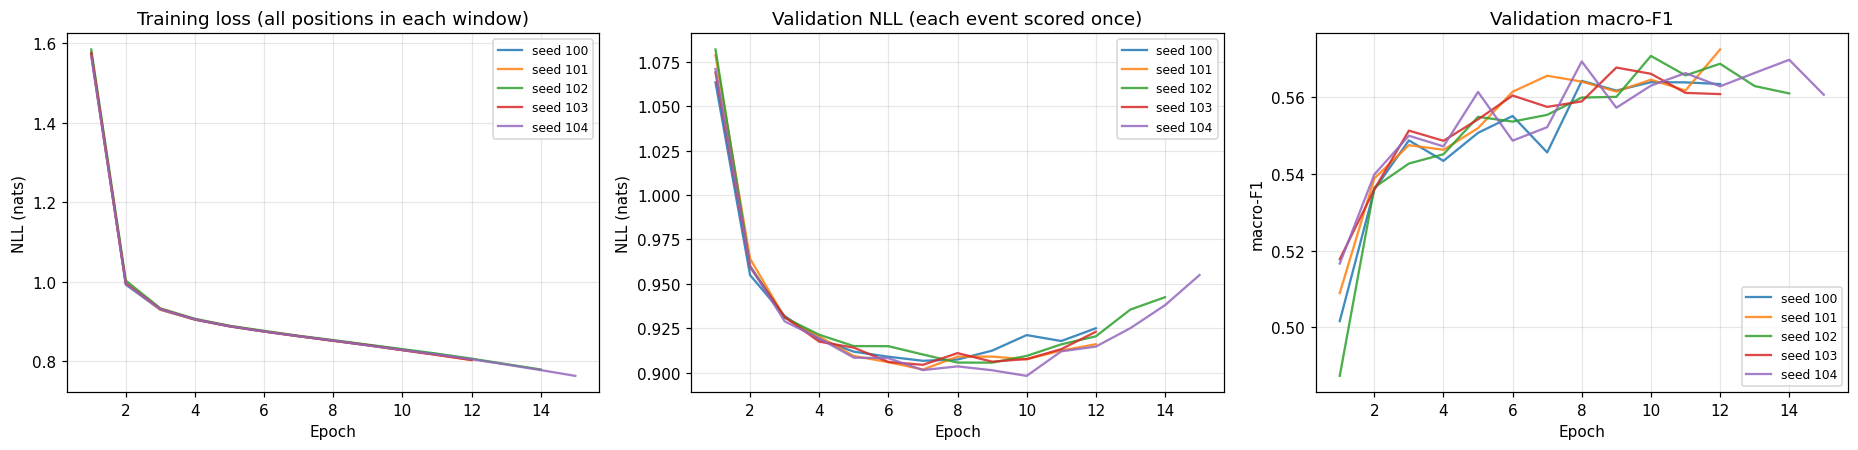

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for run_dir, seed in zip(final_run_dirs, FINAL_SEEDS):
    history = analysis.load_history(run_dir)
    axes[0].plot(history["epoch"], history["train_loss"], alpha=0.85, label=f"seed {seed}")
    axes[1].plot(history["epoch"], history["val_nll"], alpha=0.85, label=f"seed {seed}")
    axes[2].plot(history["epoch"], history["val_macro_f1"], alpha=0.85, label=f"seed {seed}")
axes[0].set_title("Training loss (all positions in each window)")
axes[1].set_title("Validation NLL (each event scored once)")
axes[2].set_title("Validation macro-F1")
for ax, label in zip(axes, ["NLL (nats)", "NLL (nats)", "macro-F1"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_final_training_curves.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Training loss (averaged over all positions of each window), validation NLL (each event scored once) and validation macro-F1 per epoch, one line per final seed.

**What to look for.** *Instability*: spikes or divergence. *Overfitting*: validation NLL turning up while training loss keeps falling; the checkpoint kept is the one at the minimum of the validation curve, not the last epoch. *Seed variability*: how far apart the five curves are at their best epoch.

**OBSERVATION.** No run diverged. The five best validation NLLs span 0.8982 to 0.9067 (mean 0.9033, SD 0.0034; Section 4). Seed 104, the lowest, also ran longest (best epoch 10).



## 3. The primary checkpoint (rule fixed in advance)

Sorted validation NLLs: 0.8982, 0.9018, 0.9044, 0.9056, 0.9067. The median is **seed 103** (validation NLL 0.904400, 911,119 parameters).

In [ ]:
ordered_final = final_table.sort_values("val_nll").reset_index(drop=True)
primary_position = len(ordered_final) // 2
PRIMARY_RUN_NAME = str(ordered_final.loc[primary_position, "run_name"])
PRIMARY_SEED = int(ordered_final.loc[primary_position, "seed"])
PRIMARY_RUN_DIR = Path(ordered_final.loc[primary_position, "run_dir"])

print(f"Primary checkpoint: seed {PRIMARY_SEED}")
print(f"  run directory  {PRIMARY_RUN_DIR}")
print(f"  validation NLL {ordered_final.loc[primary_position, 'val_nll']:.6f}")
print(f"  parameters     {int(ordered_final.loc[primary_position, 'parameters']):,}")
print("Validation NLL by seed (sorted):", [round(value, 4) for value in ordered_final["val_nll"]])

Primary checkpoint: seed 103
  run directory  /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/runs/base/transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s103
  validation NLL 0.904400
  parameters     911,119
Validation NLL by seed (sorted): [0.8982, 0.9018, 0.9044, 0.9056, 0.9067]


## 4. Every validation-based statement, recorded before the unlock

The file written here fixes the validation side of the comparison: the selected configuration, the five final runs, the primary checkpoint, the mean and SD of final validation NLL, the replacement flag from the selection, and the five-seed benchmark report.

**RESULT.** Mean validation NLL over the five final seeds: 0.9033 (seed SD 0.0034).

In [ ]:
stability_report = json.load(open(RESULTS_DIR / "11_stability_report.json"))
final_validation = {
    "selected_config": SELECTED,
    "final_seeds": FINAL_SEEDS,
    "final_runs": final_table.to_dict(orient="records"),
    "primary_run": PRIMARY_RUN_NAME,
    "primary_seed": PRIMARY_SEED,
    "validation_nll_mean": float(final_table["val_nll"].mean()),
    "validation_nll_sd": float(final_table["val_nll"].std(ddof=1)),
    "validation_accuracy_mean": float(final_table["val_accuracy"].mean()),
    "replaces_track_a_on_validation": REPLACES_TRACK_A,
    "stability_report": stability_report,
    "written_before_test_unlock": True,
    "run_mode": RUN_MODE,
    "written_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
training.save_json(RESULTS_DIR / "13_final_validation.json", final_validation)
print("Validation record written before the test split is unlocked.")
print(f"  mean validation NLL over the final seeds: {final_validation['validation_nll_mean']:.4f} "
      f"(SD {final_validation['validation_nll_sd']:.4f})")

Validation record written before the test split is unlocked.
  mean validation NLL over the final seeds: 0.9033 (SD 0.0034)


## 5. Unlocking the test split

The unlock happens here, once. If test predictions already exist they are reloaded instead of recomputed.

The Track A test predictions are **not** recomputed either. They are read from the files saved when the Track A model was evaluated on its own test split, so this notebook adds no test access beyond the single evaluation of the five final runs of the selected configuration.

**RESULT.** The unlock is logged once (2026-09-28 09:39 UTC). The selected model scores 65,009 test events; the Track A predictions cover the same 65,009 events (both use K = 16, so their evaluation views coincide), and all 65,009 are used in the comparison.

In [ ]:
final_bundle = bundle_for(FINAL_CONTEXT)
test_prediction_dir = RESULTS_DIR / "test_predictions"
test_prediction_dir.mkdir(parents=True, exist_ok=True)
test_done_flag = RESULTS_DIR / "13_test_results.json"

optimised_logits = []
if test_done_flag.exists():
    print("Test evaluation was already performed; reloading the saved predictions.")
    for file in sorted(test_prediction_dir.glob("*.npz")):
        stored = np.load(file, allow_pickle=True)
        optimised_logits.append(stored["logits"])
        optimised_rows = stored["event_rows"]
else:
    training.unlock_test_split(final_bundle, OPT_DIR, events)
    for run_dir in final_run_dirs:
        model = training.load_trained_model(run_dir, final_bundle)
        logits, _, optimised_rows = training.predict_view(model, final_bundle, "test")
        optimised_logits.append(logits)
        np.savez_compressed(test_prediction_dir / f"{run_dir.name}.npz", logits=logits,
                            event_rows=optimised_rows, model="optimised model", run=run_dir.name)
    print("Test split unlocked and evaluated. Access recorded in logs/test_access_log.jsonl.")

print("Test events scored by the optimised model:", len(optimised_rows))
print("Unlock log:")
for line in open(LOG_DIR / "test_access_log.jsonl"):
    print(" ", line.strip())

Test split unlocked and evaluated. Access recorded in logs/test_access_log.jsonl.
Test events scored by the optimised model: 65009
Unlock log:
  {"time": "2026-09-28T09:39:44.537057+00:00", "frozen_config": "/content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/config/frozen_config.json", "encoding": "T300"}


In [ ]:
track_a_prediction_dir = EXISTING_RESULTS_DIR / "test_predictions"
if not track_a_prediction_dir.exists():
    raise RuntimeError("BLOCKED: the Track A test predictions are missing. "
                       "Notebook 06 of Track A must have been executed.")

track_a_logits = []
track_a_rows = None
for file in sorted(track_a_prediction_dir.glob("*.npz")):
    stored = np.load(file, allow_pickle=True)
    if str(stored["model"]) != "B8 Transformer (final)":
        continue
    track_a_logits.append(stored["logits"])
    track_a_rows = stored["event_rows"]
if not track_a_logits:
    raise RuntimeError("BLOCKED: no Track A transformer predictions found in the test-prediction folder.")

shared_rows = np.intersect1d(optimised_rows, track_a_rows)
optimised_index = np.searchsorted(np.sort(optimised_rows), shared_rows)
track_a_index = np.searchsorted(np.sort(track_a_rows), shared_rows)
optimised_order = np.argsort(optimised_rows)
track_a_order = np.argsort(track_a_rows)

optimised_aligned = [logits[optimised_order][optimised_index] for logits in optimised_logits]
track_a_aligned = [logits[track_a_order][track_a_index] for logits in track_a_logits]
test_targets = targets[shared_rows]
test_match_ids = match_ids[shared_rows]

print(f"Optimised model test events: {len(optimised_rows)}")
print(f"Track A model test events:   {len(track_a_rows)}")
print(f"Events used in the comparison (present in both): {len(shared_rows)}")
if len(shared_rows) < min(len(optimised_rows), len(track_a_rows)):
    print("The two evaluation views differ because the context lengths differ; the comparison is "
          "restricted to the shared events, and the metrics below are computed on that set for both models.")

Optimised model test events: 65009
Track A model test events:   65009
Events used in the comparison (present in both): 65009


## 6. Headline test comparison

Both models are scored on the same 65,009 test events. For each model the table gives the mean over its five seeds, the seed SD, and a 95% match-level bootstrap interval for NLL (2,000 resamples of whole matches, on per-event NLL averaged over seeds).

**Two different uncertainties.** The bootstrap interval describes uncertainty from which matches happen to be in the test split. The seed SD describes uncertainty from initialisation.
**RESULT.**

| Model | Test NLL | seed SD | 95% CI | accuracy | top-3 | top-5 | macro-F1 | ECE |
|---|---|---|---|---|---|---|---|---|
| Track A model (frozen; 2 layers, wd 0.1) | 0.9158 | 0.0013 | [0.9035, 0.9283] | 0.6161 | 0.9445 | 0.9937 | 0.5580 | 0.0238 |
| Selected model (4 layers, wd 0.01) | 0.9148 | 0.0032 | [0.9023, 0.9273] | 0.6171 | 0.9440 | 0.9936 | 0.5585 | 0.0270 |

The selected model has slightly lower test NLL, slightly higher accuracy and macro-F1, slightly lower top-3 and top-5, and higher ECE. Its seed SD on test is larger (0.0032 against 0.0013).

In [ ]:
def headline_row(name, seed_logits):
    seed_metrics = [metrics.compute_metrics(logits, test_targets) for logits in seed_logits]
    event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in seed_logits], axis=0)
    interval = metrics.match_bootstrap_mean(event_nll, test_match_ids,
                                            n_resamples=2000 if RUN_MODE == "full" else 50)
    return {"model": name, "seeds": len(seed_logits),
            "NLL": float(np.mean([m["nll"] for m in seed_metrics])),
            "NLL seed SD": float(np.std([m["nll"] for m in seed_metrics], ddof=1)) if len(seed_metrics) > 1 else 0.0,
            "NLL 95% CI": f"[{interval['ci_low']:.4f}, {interval['ci_high']:.4f}]",
            "accuracy": float(np.mean([m["accuracy"] for m in seed_metrics])),
            "top-3": float(np.mean([m["top3_accuracy"] for m in seed_metrics])),
            "top-5": float(np.mean([m["top5_accuracy"] for m in seed_metrics])),
            "macro-F1": float(np.mean([m["macro_f1"] for m in seed_metrics])),
            "ECE": float(np.mean([m["ece"] for m in seed_metrics]))}


headline = pd.DataFrame([headline_row("Track A model (frozen)", track_a_aligned),
                         headline_row("Optimised model", optimised_aligned)]).set_index("model")
headline.round(4)

,seeds,NLL,NLL seed SD,NLL 95% CI,accuracy,top-3,top-5,macro-F1,ECE
model,,,,,,,,,
Track A model (frozen),5,0.9158,0.0013,"[0.9035, 0.9283]",0.6161,0.9445,0.9937,0.5580,0.0238
Optimised model,5,0.9148,0.0032,"[0.9023, 0.9273]",0.6171,0.9440,0.9936,0.5585,0.0270


In [ ]:
optimised_event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in optimised_aligned], axis=0)
track_a_event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in track_a_aligned], axis=0)
difference = optimised_event_nll - track_a_event_nll
test_interval = metrics.match_bootstrap_mean(difference, test_match_ids,
                                             n_resamples=2000 if RUN_MODE == "full" else 50)

optimised_seed_means = [float(metrics.per_event_nll(logits, test_targets).mean()) for logits in optimised_aligned]
track_a_seed_means = [float(metrics.per_event_nll(logits, test_targets).mean()) for logits in track_a_aligned]
seeds_separated = max(optimised_seed_means) < min(track_a_seed_means)
better_beyond_noise = bool(test_interval["ci_high"] < 0 and seeds_separated)

print(f"Optimised minus Track A on test: {test_interval['mean']:+.4f} nats "
      f"[{test_interval['ci_low']:+.4f}, {test_interval['ci_high']:+.4f}]")
print(f"Optimised seed means: {[round(value, 4) for value in optimised_seed_means]}")
print(f"Track A seed means:   {[round(value, 4) for value in track_a_seed_means]}")
print(f"Seeds completely separated: {seeds_separated}")
print(f"Better beyond noise under the Track A rule: {better_beyond_noise}")

Optimised minus Track A on test: -0.0010 nats [-0.0027, +0.0006]
Optimised seed means: [0.9193, 0.9105, 0.9156, 0.9139, 0.9147]
Track A seed means:   [0.918, 0.9145, 0.9158, 0.9157, 0.9153]
Seeds completely separated: False
Better beyond noise under the Track A rule: False


**What is measured.** The paired per-event difference in test NLL (selected minus Track A), with a 95% match-level bootstrap interval, and the per-seed test NLL of both models — i.e. the decision rule applied on test.

**RESULT.** Difference −0.0010 nats, 95% interval [−0.0027, +0.0006]. Selected-model seed means 0.9105–0.9193; Track A seed means 0.9145–0.9180. The seeds are not separated. **Not better beyond noise.**

**INTERPRETATION.** On validation the selected configuration was −0.0033 [−0.0048, −0.0020] against the Track A reference, with overlapping seeds, and was not proposed as a replacement. On test the difference is smaller (−0.0010) and the interval includes zero. The test data do not distinguish the two models.



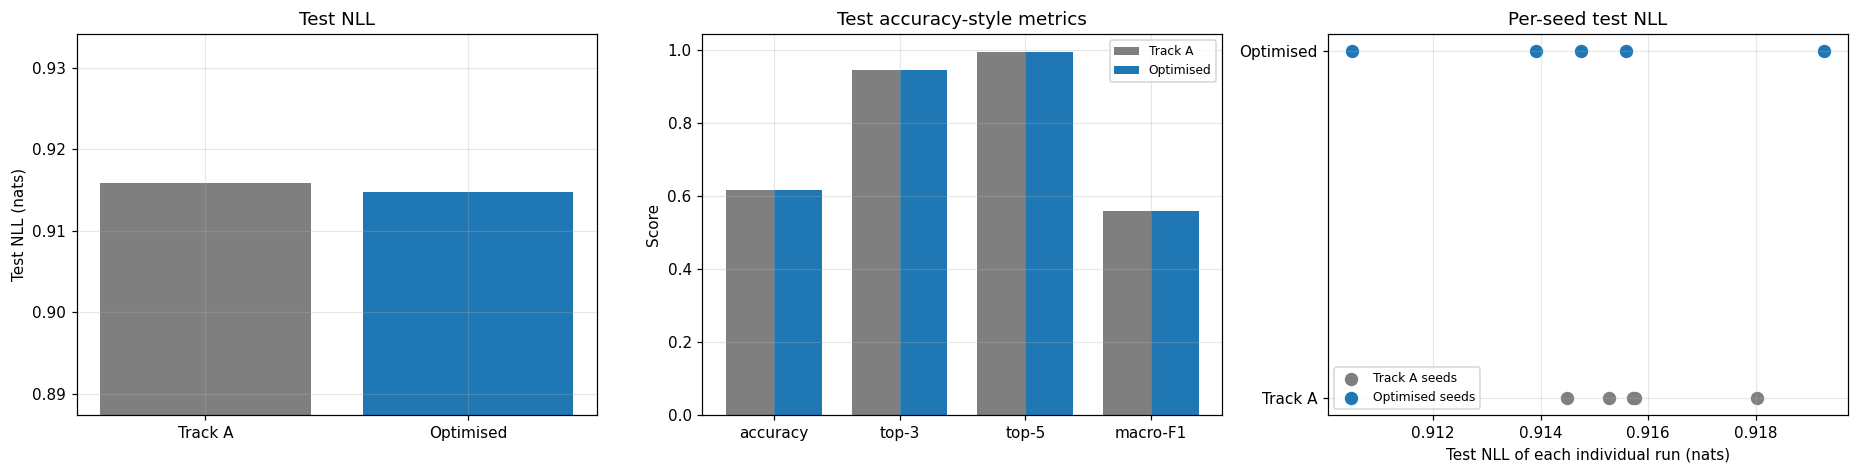

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

axes[0].bar(["Track A", "Optimised"], [headline.loc["Track A model (frozen)", "NLL"],
                                       headline.loc["Optimised model", "NLL"]],
            color=["tab:grey", "tab:blue"])
axes[0].set_ylabel("Test NLL (nats)")
axes[0].set_title("Test NLL")
axes[0].set_ylim(min(headline["NLL"]) * 0.97, max(headline["NLL"]) * 1.02)

metric_names = ["accuracy", "top-3", "top-5", "macro-F1"]
positions = np.arange(len(metric_names))
axes[1].bar(positions - 0.19, [headline.loc["Track A model (frozen)", name] for name in metric_names],
            width=0.38, label="Track A", color="tab:grey")
axes[1].bar(positions + 0.19, [headline.loc["Optimised model", name] for name in metric_names],
            width=0.38, label="Optimised", color="tab:blue")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(metric_names)
axes[1].set_ylabel("Score")
axes[1].set_title("Test accuracy-style metrics")
axes[1].legend(fontsize=8)

axes[2].scatter(track_a_seed_means, np.zeros(len(track_a_seed_means)), s=60, color="tab:grey", label="Track A seeds")
axes[2].scatter(optimised_seed_means, np.ones(len(optimised_seed_means)), s=60, color="tab:blue", label="Optimised seeds")
axes[2].set_yticks([0, 1])
axes[2].set_yticklabels(["Track A", "Optimised"])
axes[2].set_xlabel("Test NLL of each individual run (nats)")
axes[2].set_title("Per-seed test NLL")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_test_comparison.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Left: test NLL of the two models (note the truncated vertical axis). Centre: accuracy, top-3, top-5 and macro-F1 side by side. Right: the test NLL of each individual run, one row per model.

**What it shows.** The right panel settles the comparison visually: the five Track A points (0.9145–0.9180) lie inside the range of the five selected-model points (0.9105–0.9193). The centre panel shows no metric on which the two models differ by more than a few thousandths.



## 7. Per-class behaviour and calibration on test

The headline metrics average over a very uneven class distribution. The two panels below show where any difference between the models lies (per-class F1, mean over the five seeds of each model) and how reliable the predicted probabilities are.

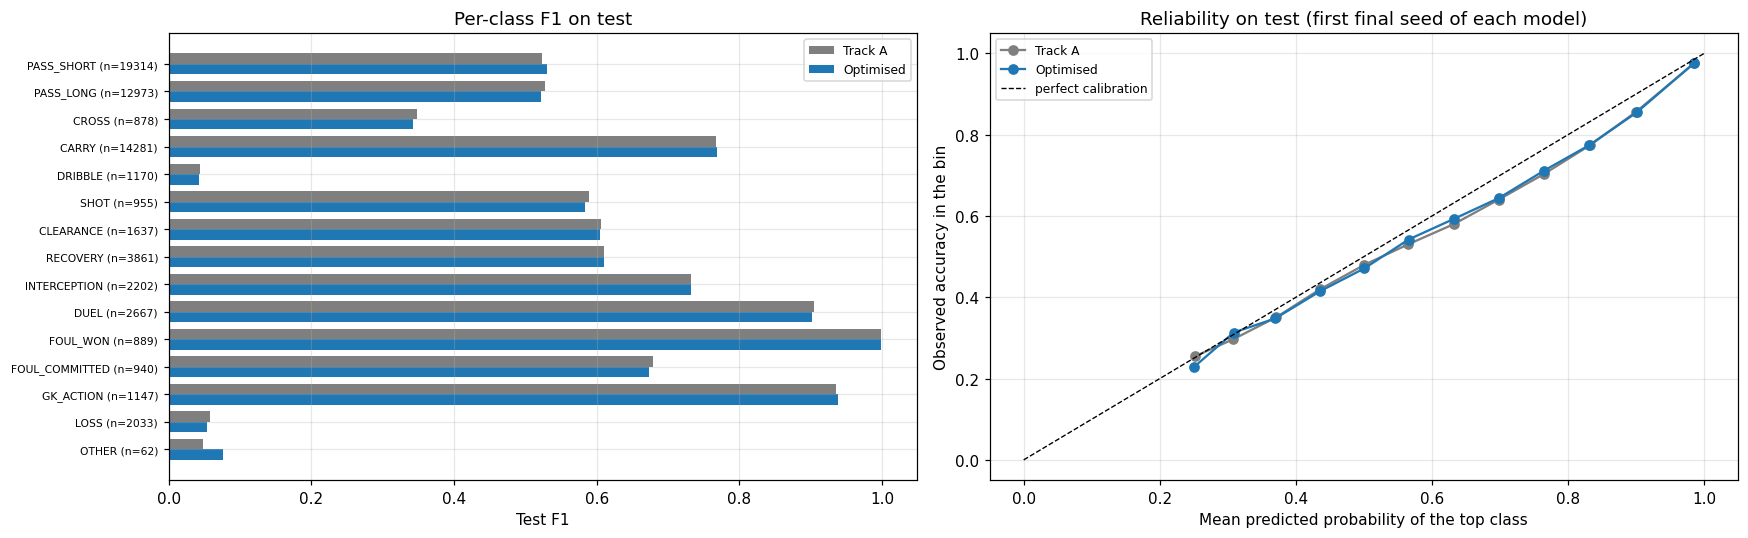

         class  test events  Track A F1  Optimised F1  difference
    PASS_SHORT        19314      0.5228        0.5298      0.0070
     PASS_LONG        12973      0.5269        0.5224     -0.0045
         CROSS          878      0.3483        0.3421     -0.0062
         CARRY        14281      0.7672        0.7688      0.0016
       DRIBBLE         1170      0.0434        0.0417     -0.0018
          SHOT          955      0.5888        0.5841     -0.0047
     CLEARANCE         1637      0.6057        0.6043     -0.0014
      RECOVERY         3861      0.6097        0.6098      0.0001
  INTERCEPTION         2202      0.7321        0.7320     -0.0000
          DUEL         2667      0.9050        0.9019     -0.0032
      FOUL_WON          889      0.9994        0.9993     -0.0001
FOUL_COMMITTED          940      0.6796        0.6731     -0.0065
     GK_ACTION         1147      0.9361        0.9387      0.0026
          LOSS         2033      0.0573        0.0535     -0.0037
         O

In [ ]:
optimised_per_class = np.mean([metrics.compute_metrics(logits, test_targets)["per_class_f1"]
                               for logits in optimised_aligned], axis=0)
track_a_per_class = np.mean([metrics.compute_metrics(logits, test_targets)["per_class_f1"]
                             for logits in track_a_aligned], axis=0)
class_names = list(data.ACTION_NAMES) if hasattr(data, "ACTION_NAMES") else [str(i) for i in range(len(optimised_per_class))]
class_support = np.bincount(test_targets, minlength=len(optimised_per_class))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))
positions = np.arange(len(class_names))
axes[0].barh(positions - 0.19, track_a_per_class, height=0.38, label="Track A", color="tab:grey")
axes[0].barh(positions + 0.19, optimised_per_class, height=0.38, label="Optimised", color="tab:blue")
axes[0].set_yticks(positions)
axes[0].set_yticklabels([f"{name} (n={count})" for name, count in zip(class_names, class_support)], fontsize=7)
axes[0].invert_yaxis()
axes[0].set_xlabel("Test F1")
axes[0].set_title("Per-class F1 on test")
axes[0].legend(fontsize=8)

for name, aligned, colour in [("Track A", track_a_aligned, "tab:grey"), ("Optimised", optimised_aligned, "tab:blue")]:
    probabilities = np.exp(metrics.log_softmax(aligned[0]))
    table = pd.DataFrame(metrics.reliability_table(probabilities, test_targets)).dropna()
    axes[1].plot(table["mean_confidence"], table["accuracy"], marker="o", color=colour, label=name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=0.9, label="perfect calibration")
axes[1].set_xlabel("Mean predicted probability of the top class")
axes[1].set_ylabel("Observed accuracy in the bin")
axes[1].set_title("Reliability on test (first final seed of each model)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_per_class_and_calibration.png", bbox_inches="tight")
plt.show()

per_class_table = pd.DataFrame({"class": class_names, "test events": class_support,
                                "Track A F1": track_a_per_class, "Optimised F1": optimised_per_class,
                                "difference": optimised_per_class - track_a_per_class})
print(per_class_table.round(4).to_string(index=False))

**What are we looking at?** Left: test F1 for each action class and both models, with the number of test events of each class in the label. Right: reliability curves (observed accuracy against predicted confidence, 15 bins) for one run of each model — the first run in each model's list, not the primary checkpoint. The dashed diagonal is perfect calibration.

**RESULT.** Per-class F1 differences (selected − Track A) are within ±0.007 for every class except OTHER (+0.0288). OTHER has 62 test events. The largest differences among frequent classes are PASS_SHORT (+0.0070, 19,314 events), FOUL_COMMITTED (−0.0065) and CROSS (−0.0062). DRIBBLE (F1 ≈ 0.04) and LOSS (≈ 0.05) remain essentially unpredicted by both models.

**INTERPRETATION.** The two models behave almost identically class by class. The only noticeable difference is in OTHER, a class whose F1 on 62 events is too imprecise to support any statement. FOUL_WON is near 0.999 for both models; almost every FOUL_WON event is the second half of a same-moment Foul Committed / Foul Won pair, so this F1 reflects annotation, not modelling skill.


## 8. Result record

The selected model has the lower test NLL, but the difference is not separated from noise under the decision rule; the test data do not distinguish the two models.

In [ ]:
test_results = {
    "run_mode": RUN_MODE,
    "selected_config": SELECTED,
    "final_seeds": FINAL_SEEDS,
    "primary_run": PRIMARY_RUN_NAME,
    "primary_seed": PRIMARY_SEED,
    "n_test_events_optimised": int(len(optimised_rows)),
    "n_test_events_track_a": int(len(track_a_rows)),
    "n_test_events_compared": int(len(shared_rows)),
    "headline": headline.reset_index().to_dict(orient="records"),
    "difference_optimised_minus_track_a": test_interval["mean"],
    "difference_ci_low": test_interval["ci_low"],
    "difference_ci_high": test_interval["ci_high"],
    "optimised_seed_test_nll": optimised_seed_means,
    "track_a_seed_test_nll": track_a_seed_means,
    "seeds_completely_separated": bool(seeds_separated),
    "better_beyond_noise_on_test": better_beyond_noise,
    "replaces_track_a_on_validation": REPLACES_TRACK_A,
    "per_class_f1": per_class_table.to_dict(orient="records"),
    "written_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
if not test_done_flag.exists():
    training.save_json(test_done_flag, test_results)
    print("Test results saved:", test_done_flag)
else:
    print("Test results were saved at the first evaluation and are not overwritten.")

if better_beyond_noise:
    verdict = ("The optimised model predicts held-out events better than the frozen Track A model "
               "under the Track A decision rule.")
elif test_interval["mean"] < 0:
    verdict = ("The optimised model has the lower test NLL, but the difference is not separated "
               "from noise under the Track A decision rule; the test data do not distinguish the "
               "two models.")
else:
    verdict = ("The optimised model does not have a lower test NLL than the frozen Track A model.")
print("\n" + verdict)

Test results saved: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/results/13_test_results.json

The optimised model has the lower test NLL, but the difference is not separated from noise under the Track A decision rule; the test data do not distinguish the two models.


In [ ]:
modified = []
snapshot_path = MANIFEST_DIR / "track_a_snapshot.json"
if snapshot_path.exists():
    for name, digest in json.load(open(snapshot_path)).items():
        path = EXISTING_DIR / name
        if path.exists() and file_sha256(path) != digest:
            modified.append(name)
print("Track A files modified by this experiment:", modified if modified else "none")
print("Test-split accesses recorded:", sum(1 for _ in open(LOG_DIR / "test_access_log.jsonl")))

Track A files modified by this experiment: none
Test-split accesses recorded: 1


## 9. Summary

| Item | Result |
|---|---|
| Final runs | 4L_2H_K16, seeds 100–104; none diverged |
| Validation NLL (final seeds) | mean 0.9033, SD 0.0034 |
| Primary checkpoint | seed 103 (median), validation NLL 0.904400 |
| Test events | 65,009 (same events for both models) |
| Test NLL, selected model | 0.9148 (seed SD 0.0032) [0.9023, 0.9273] |
| Test NLL, Track A model | 0.9158 (seed SD 0.0013) [0.9035, 0.9283] |
| Selected − Track A (test) | −0.0010 [−0.0027, +0.0006], seeds not separated: not better beyond noise |
| Replacement of the Track A model | not supported on validation; test agrees |
| Test accesses by this experiment | 1 |
| Track A files modified | none |
